# Week 8, notebook 0: Wells in FloPy

**HWRS 564a · Fall 2026**

In Week 7 you developed steady state models. This notebook looks at wells
more closely, on a model simple enough that we can check MODFLOW against
formulas you can work out by hand.

There are three parts:

1. How to describe wells to FloPy with the `WEL` package
2. One well in an aquifer with no other flow, compared with the Thiem equation
3. One well in an aquifer with regional flow, and how its capture zone grows
   with the pumping rate

## How to use this notebook

Run each cell with **Shift+Enter**. Cells marked `# YOUR TURN` have something
for you to write. Cells marked `# CHECK` test your answer and raise an error if
it is wrong.

## Learning objectives

By the end of this notebook you can:

1. Write the `stress_period_data` for one or more wells and confirm the
   pumping in the water budget
2. Compare model heads near a well with the Thiem equation
3. Trace the capture zone of a well in regional flow
4. Estimate the width of a capture zone from the pumping rate, the
   transmissivity, and the regional gradient

---

## Part 1: Setup

In [1]:
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator

ROOT = Path("../..")  # course repo root
MF_EXE = ROOT / "modflow" / "mf2005"
assert MF_EXE.exists(), (
    f"MODFLOW binary not found at {MF_EXE}. Run ./postbuild.sh from a terminal."
)

RUN = ROOT / "_run"

print("ready")

ready


---

## Part 2: The model

One confined layer, 2 km by 2 km, with 20 m cells.

| | |
|---|---|
| Grid | 101 rows, 101 columns, 20 m cells |
| Layer | top at 0 m, bottom at −20 m, so 20 m thick |
| Hydraulic conductivity | 10 m/d |
| Transmissivity | $T = Kb$ = 10 × 20 = 200 m²/d |

The grid has an odd number of rows and columns so that one cell sits exactly in
the middle: row 50, column 50.

The function below builds and runs the model. It takes:

- `wells`: a list of wells, in the format described in Part 3. Use an empty
  list for no wells.
- `west_head` and `east_head`: the constant heads on the west and east edges
- `constant_head_all_sides`: if `True`, the north and south edges are constant
  head too. If `False`, they are no-flow boundaries.

In [2]:
N = 101                  # rows and columns
DELR = 20.0              # cell size, m
HK = 10.0                # hydraulic conductivity, m/d
TOP, BOTM = 0.0, -20.0   # layer top and bottom, m
T = HK * (TOP - BOTM)    # transmissivity, m2/d
MID = N // 2             # row and column of the middle cell


def run_model(name, wells, west_head=10.0, east_head=10.0,
              constant_head_all_sides=False):
    """Build and run the model. Returns (model, head, workspace)."""
    ws = RUN / f"week08_wells_{name}"
    ws.mkdir(parents=True, exist_ok=True)

    m = flopy.modflow.Modflow(name, model_ws=str(ws), exe_name=str(MF_EXE))
    flopy.modflow.ModflowDis(m, nlay=1, nrow=N, ncol=N, delr=DELR, delc=DELR,
                             top=TOP, botm=BOTM, nper=1, steady=True)

    ibound = np.ones((1, N, N), dtype=int)
    ibound[:, :, 0] = -1           # west edge
    ibound[:, :, -1] = -1          # east edge
    if constant_head_all_sides:
        ibound[:, 0, :] = -1       # north edge
        ibound[:, -1, :] = -1      # south edge

    # starting head: a straight line from the west head to the east head
    strt = np.ones((1, N, N)) * np.linspace(west_head, east_head, N)
    flopy.modflow.ModflowBas(m, ibound=ibound, strt=strt)

    flopy.modflow.ModflowLpf(m, hk=HK, laytyp=0, ipakcb=53)
    if wells:
        flopy.modflow.ModflowWel(m, stress_period_data={0: wells}, ipakcb=53)
    flopy.modflow.ModflowPcg(m, rclose=1e-3)
    flopy.modflow.ModflowOc(m, stress_period_data={(0, 0): ["save head", "save budget"]})

    m.write_input()
    success, buff = m.run_model(silent=True, report=True)
    assert success, "MODFLOW did not finish:\n" + "\n".join(buff[-10:])
    head = flopy.utils.HeadFile(str(ws / f"{name}.hds")).get_data()
    return m, head, ws


print(f"transmissivity T = {T:.0f} m2/d")

transmissivity T = 200 m2/d


---

## Part 3: The `WEL` package

FloPy takes wells as a dictionary called `stress_period_data`. The key is the
stress period number, and the value is a list with one entry per well:

```python
{0: [[layer, row, column, rate],
     [layer, row, column, rate]]}
```

- Layer, row, and column count from zero.
- A **negative** rate takes water out of the cell. A positive rate injects
  water.
- The rate is in the model's units. Here that is m³/d.

Our `run_model` function builds the dictionary for stress period 0, so you only
pass it the list. Here is one well in the middle cell, pumping 400 m³/d. All
four edges are held at 10 m.

In [3]:
one_well = [[0, MID, MID, -400.0]]

m_one, head_one, ws_one = run_model("one_well", one_well, constant_head_all_sides=True)

print("what FloPy stored for stress period 0:")
print(m_one.wel.stress_period_data[0])

what FloPy stored for stress period 0:
[(0, 50, 50, -400.)]


FloPy stores the wells as a table with columns `k`, `i`, `j`, and `flux`. Those
are MODFLOW's names for layer, row, column, and rate.

Always confirm the pumping in the water budget. A well in the wrong cell, or
with the wrong sign, still runs.

In [4]:
def print_budget(ws, name):
    """Print the budget terms that are not zero."""
    budget = flopy.utils.MfListBudget(str(ws / f"{name}.list")).get_data()
    for row in budget:
        term = row["name"].decode()
        if term != "tslen" and abs(row["value"]) > 1e-6:
            print(f"  {term:20s} {row['value']:10.2f}")


print_budget(ws_one, "one_well")

  CONSTANT_HEAD_IN         400.00
  TOTAL_IN                 400.00
  WELLS_OUT               -400.00
  TOTAL_OUT               -400.00
  IN-OUT                    -0.00


`WELLS_OUT` is 400 m³/d, which is what we asked for. The model is at steady
state, so that water has to come from somewhere, and the only source is the
constant-head cells: `CONSTANT_HEAD_IN` is also 400 m³/d.

Now the heads. `plot_bc("WEL")` marks the cells that have a well.

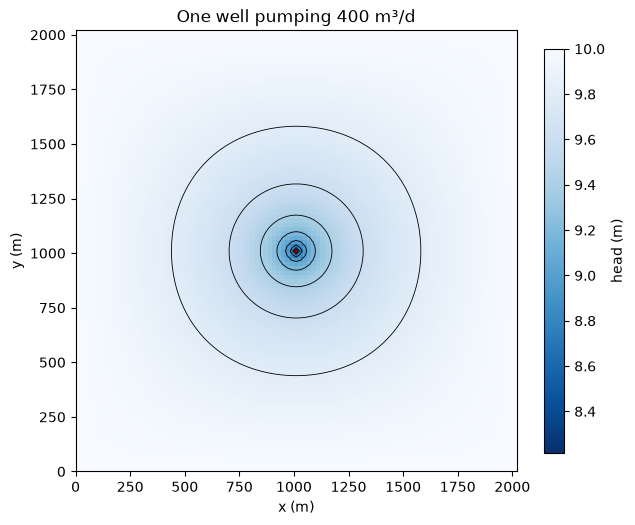

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
mapview = flopy.plot.PlotMapView(model=m_one, layer=0, ax=ax)
im = mapview.plot_array(head_one, cmap="Blues_r")
mapview.contour_array(head_one, levels=np.arange(8.4, 10.0, 0.2), colors="k", linewidths=0.6)
mapview.plot_bc("WEL", color="red")
fig.colorbar(im, ax=ax, label="head (m)", shrink=0.85)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("One well pumping 400 m³/d")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

The contours are circles around the well, which is what you would expect when
nothing else is driving flow.

### YOUR TURN 1

Run a model with two wells in row 50:

- a well in column 30 pumping 300 m³/d
- a well in column 70 **injecting** 100 m³/d

Write the list, then run it with the name `"two_wells"` and all four edges at
constant head.

- `two_wells`: the list of wells
- `m_two`, `head_two`, `ws_two`: the result of `run_model`

In [ ]:
# YOUR TURN
two_wells = ...
m_two, head_two, ws_two = ...

In [ ]:
# CHECK
spd = m_two.wel.stress_period_data[0]
assert len(spd) == 2, f"expected 2 wells, got {len(spd)}"
by_col = {int(w["j"]): float(w["flux"]) for w in spd}
assert set(by_col) == {30, 70}, f"wells should be in columns 30 and 70, got {sorted(by_col)}"
assert all(int(w["i"]) == 50 for w in spd), "both wells should be in row 50"
assert by_col[30] == -300.0, f"the column 30 well should pump 300 m3/d (negative), got {by_col[30]}"
assert by_col[70] == 100.0, f"the column 70 well should inject 100 m3/d (positive), got {by_col[70]}"
assert head_two[0, 50, 30] < 10.0 < head_two[0, 50, 70]
print_budget(ws_two, "two_wells")
print(f"\nhead at the pumping well:   {head_two[0, 50, 30]:.2f} m")
print(f"head at the injection well: {head_two[0, 50, 70]:.2f} m")

The budget now has `WELLS_IN` and `WELLS_OUT`. Head is below 10 m at the
pumping well and above 10 m at the injection well.

---

## Part 4: Checking against the Thiem equation

For steady flow to a well in a confined aquifer, the Thiem equation gives the
difference in head between two distances from the well, $r_1$ and $r_2$:

$$h(r_2) - h(r_1) = \frac{Q}{2\pi T}\ln\frac{r_2}{r_1}$$

$Q$ is the pumping rate as a positive number. Head rises as you move away from
the well, quickly at first and then more slowly.

To compare with the model, take the heads along row 50 from the well cell
eastward. Cell centres are 20 m apart, so those cells are at 0, 20, 40, ... m
from the well.

In [ ]:
Q = 400.0                                   # m3/d
n_cells = 41                                # out to 800 m
r = np.arange(n_cells) * DELR               # distance from the well, m
model_head = head_one[0, MID, MID:MID + n_cells]

for i in [0, 1, 2, 5, 10, 20, 40]:
    print(f"r = {r[i]:5.0f} m   model head = {model_head[i]:.3f} m")

### YOUR TURN 2

Use the Thiem equation to predict the head at every distance in `r`, starting
from the model head at 200 m.

- `r_ref`: 200.0
- `h_ref`: the model head at 200 m. That is element 10 of `model_head`.
- `thiem_head`: an array, the head predicted by Thiem at each distance in
  `r[1:]`

Rearranged, the equation is
$h(r) = h_{ref} + \frac{Q}{2\pi T}\ln\frac{r}{r_{ref}}$.
We skip `r[0]` because the log of zero is not defined.

In [ ]:
# YOUR TURN
r_ref = ...
h_ref = ...
thiem_head = ...

In [ ]:
# CHECK
thiem_head = np.asarray(thiem_head)
assert thiem_head.shape == (n_cells - 1,), f"expected {n_cells - 1} values, got {thiem_head.shape}"
assert abs(thiem_head[9] - model_head[10]) < 1e-9, "Thiem should equal the model head at 200 m"
expected = model_head[10] + Q / (2 * np.pi * T) * np.log(r[1:] / 200.0)
assert np.allclose(thiem_head, expected), "check the formula"
difference = model_head[1:] - thiem_head
print(f"largest difference between model and Thiem, 20 to 800 m: {np.abs(difference).max():.3f} m")

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(r[1:], thiem_head, "-", color="#0C234B", label="Thiem equation")
ax.plot(r[1:], model_head[1:], "o", color="#AB0520", ms=4, label="MODFLOW cells")
ax.plot(r[0], model_head[0], "s", color="#AB0520", ms=8, mfc="none", label="MODFLOW well cell")
ax.set_xlabel("distance from the well (m)")
ax.set_ylabel("head (m)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The model follows the Thiem curve to within about a centimetre. It drifts
away slightly near 800 m, because the model's boundary is a square and Thiem
assumes a circle.

The well cell is the open square at $r = 0$. The Thiem curve keeps falling as
$r$ approaches zero, but the model has one head for the whole 20 m cell. That
head is not the water level in the well. The next notebook looks at how it
depends on the cell size.

---

## Part 5: A well in regional flow

Now let the groundwater flow from west to east. Set the west edge to 10 m and
the east edge to 0 m, with no-flow boundaries on the north and south. The edges
are 2,000 m apart, so the regional gradient is

$$i = \frac{10 - 0}{2000} = 0.005$$

Without a well, head falls in a straight line and every metre of aquifer
width carries the same flow:

$$T\,i = 200 \times 0.005 = 1 \text{ m}^3\text{/d per metre of width}$$

In [ ]:
GRADIENT = 10.0 / 2000.0

m_none, head_none, ws_none = run_model("no_well", [], west_head=10.0, east_head=0.0)
print_budget(ws_none, "no_well")
print(f"\nT x i x width = {T * GRADIENT * N * DELR:.0f} m3/d")

The flow through the model matches $T\,i$ times the width of the model.

Now add the well. Water that enters from the west either reaches the well or
passes by to the east edge. The **capture zone** is the part of the aquifer
whose water ends up in the well.

To find it, we start particles in a ring around the well and follow the flow
**backwards**. Every path found that way is a path that leads to the well. The
function below does that. It needs the flow between cells, which MODFLOW saves
in the `.cbc` file, and FloPy turns into a flow direction at each cell centre.

In [ ]:
def trace_to_well(m, ws, name, n_particles=120, step=5.0, n_steps=500):
    """Follow the flow backwards from a ring around the middle cell.

    Returns an array of shape (n_steps, n_particles, 2) holding the x and y of
    each particle at each step. Positions are NaN after a particle leaves the
    model.
    """
    cbc = flopy.utils.CellBudgetFile(str(ws / f"{name}.cbc"))
    frf = cbc.get_data(text="FLOW RIGHT FACE")[0]
    fff = cbc.get_data(text="FLOW FRONT FACE")[0]
    qx, qy, _ = flopy.utils.postprocessing.get_specific_discharge((frf, fff, None), m)

    # cell centres, with y increasing to the north (row 0 is the north edge)
    x = (np.arange(N) + 0.5) * DELR
    y = (np.arange(N) + 0.5) * DELR
    fx = RegularGridInterpolator((y, x), qx[0][::-1], bounds_error=False)
    fy = RegularGridInterpolator((y, x), qy[0][::-1], bounds_error=False)

    angle = np.linspace(0, 2 * np.pi, n_particles, endpoint=False)
    pos = np.column_stack([x[MID] + 1.5 * DELR * np.cos(angle),
                           y[MID] + 1.5 * DELR * np.sin(angle)])
    paths = np.full((n_steps, n_particles, 2), np.nan)
    for k in range(n_steps):
        paths[k] = pos
        q = np.column_stack([fx(pos[:, ::-1]), fy(pos[:, ::-1])])
        speed = np.hypot(q[:, 0], q[:, 1])
        pos = pos - step * q / speed[:, None]        # minus: against the flow
    return paths


def plot_capture(ax, m, head, paths, title):
    mapview = flopy.plot.PlotMapView(model=m, layer=0, ax=ax)
    mapview.contour_array(head, levels=np.arange(0, 10.1, 0.5), colors="gray", linewidths=0.6)
    ax.plot(paths[:, :, 0], paths[:, :, 1], color="#1E5288", linewidth=0.6)
    mapview.plot_bc("WEL", color="red")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(title)
    ax.set_aspect("equal")


well_400 = [[0, MID, MID, -400.0]]
m_400, head_400, ws_400 = run_model("flow_400", well_400, west_head=10.0, east_head=0.0)
paths_400 = trace_to_well(m_400, ws_400, "flow_400")

fig, ax = plt.subplots(figsize=(6.5, 6))
plot_capture(ax, m_400, head_400, paths_400, "Capture zone, 400 m³/d")
plt.tight_layout()
plt.show()

The grey lines are head contours and the blue lines are flow paths that end at
the well. Flow is from left to right. The blue region is the capture zone.

Two things to notice:

- The capture zone extends upstream to the west edge, and gets wider going
  upstream.
- It extends only a short way downstream of the well. The point where it ends
  is called the **stagnation point**. Water east of it flows away from the
  well.

Both can be estimated by hand.

**Width.** The well takes $Q$. Each metre of aquifer width carries $T\,i$. So
far upstream, the well needs a strip of aquifer this wide:

$$w = \frac{Q}{T\,i}$$

**Stagnation point.** The well pulls water toward it at a rate that falls off
with distance. At the stagnation point that pull exactly balances the regional
flow. The distance downstream from the well is

$$x_s = \frac{Q}{2\pi T\,i}$$

### YOUR TURN 3

Write two functions that return these estimates. Use the variables `T` and
`GRADIENT`.

- `capture_width(Q)`: the width far upstream, in metres
- `stagnation_distance(Q)`: the distance from the well to the stagnation point,
  in metres

`Q` is the pumping rate as a positive number, in m³/d.

In [ ]:
# YOUR TURN
def capture_width(Q):
    return ...


def stagnation_distance(Q):
    return ...

In [ ]:
# CHECK
assert abs(capture_width(400.0) - 400.0) < 1e-6, f"got {capture_width(400.0)}"
assert abs(capture_width(100.0) - 100.0) < 1e-6, f"got {capture_width(100.0)}"
assert abs(stagnation_distance(400.0) - 400.0 / (2 * np.pi)) < 1e-6, f"got {stagnation_distance(400.0)}"
print(f"at 400 m3/d: width {capture_width(400.0):.0f} m, "
      f"stagnation point {stagnation_distance(400.0):.0f} m downstream")

### Three pumping rates

Now run the model at 200, 400, and 800 m³/d and measure both quantities from
the model:

- the width of the capture zone where it meets the west edge
- the stagnation point, which lies between the last cell face east of the
  well with flow toward the well and the first one with flow toward the east

In [ ]:
def measure(m, ws, name, paths):
    """Capture-zone width at the west edge, and the two cell faces that
    bracket the stagnation point (distances east of the well)."""
    last = np.array([p[~np.isnan(p[:, 0])][-1] for p in paths.transpose(1, 0, 2)])
    reached_west = last[last[:, 0] < 2 * DELR]
    width = float(np.ptp(reached_west[:, 1]))

    cbc = flopy.utils.CellBudgetFile(str(ws / f"{name}.cbc"))
    frf = cbc.get_data(text="FLOW RIGHT FACE")[0]
    east_of_well = frf[0, MID, MID:]              # flow through each cell's east face
    k = int(np.argmax(east_of_well > 0))          # first face with flow to the east
    return width, ((k - 0.5) * DELR, (k + 0.5) * DELR)


rates = [200.0, 400.0, 800.0]
results = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, rate in zip(axes, rates):
    name = f"flow_{int(rate)}"
    m, head, ws = run_model(name, [[0, MID, MID, -rate]], west_head=10.0, east_head=0.0)
    paths = trace_to_well(m, ws, name)
    results[rate] = measure(m, ws, name, paths)
    plot_capture(ax, m, head, paths, f"{rate:.0f} m³/d")
plt.tight_layout()
plt.show()

print("  rate     width at west edge    estimate Q/(T i)    stagnation point    estimate")
for rate in rates:
    width, (lo, hi) = results[rate]
    print(f"{rate:6.0f}   {width:14.0f} m   {capture_width(rate):14.0f} m   "
          f"{lo:7.0f} to {hi:3.0f} m   {stagnation_distance(rate):7.0f} m")

Doubling the pumping rate doubles the width of the capture zone and doubles
the distance to the stagnation point. Both estimates are proportional to $Q$.

The stagnation distances from the model bracket the estimates.

The widths from the model are smaller than $Q/(T\,i)$, and the gap grows with
the pumping rate. That is expected. $Q/(T\,i)$ is the width far upstream, and
the capture zone is still widening where it meets the west edge of our model,
1 km from the well. At the well itself the capture zone is half as wide,
$Q/(2T\,i)$.

### YOUR TURN 4

A contaminated area 600 m wide lies far upstream of the well. What pumping rate
would make the capture zone that wide?

- `rate_needed`: the pumping rate in m³/d, as a positive number

In [ ]:
# YOUR TURN
rate_needed = ...

In [ ]:
# CHECK
assert abs(capture_width(rate_needed) - 600.0) < 1e-6, (
    f"at {rate_needed} m3/d the capture zone is {capture_width(rate_needed):.0f} m wide"
)
print(f"pumping rate needed: {rate_needed:.0f} m3/d")

These estimates assume a uniform aquifer, a uniform regional gradient, no
recharge, and a boundary far away. Real sites break all of those, which is why
capture zones are usually worked out with a model. The formulas are still worth
knowing: they tell you roughly what the model should give, and what happens to
the answer if $Q$, $T$, or $i$ changes.

---

## Before you leave

1. *Kernel → Restart Kernel and Run All Cells*
2. Fix anything that breaks
3. Save

## Next

`week08_01_discretization_boundaries.ipynb` puts a well in a larger model of
the Tucson basin and asks how small the cells need to be.

## Stuck?

- This notebook runs seven MODFLOW models. Each takes a second or two.
- If `run_model` stops with "MODFLOW did not finish", check the signs and the
  row and column numbers in your well list. Rows and columns run from 0 to 100.
- Office hours: Tuesdays 1:00–2:00pm, Harshbarger 322B.